# Engagement 1 — Exploratory Data Analysis

**Client:** GuardianShield Insurance (fictional)
**Engagement:** Customer Renewal Prediction
**Notebook:** 01 — EDA
**Author:** Yinka Adebimpe

## Purpose

Understand the structure of the renewal dataset before modelling:

1. Distribution of the target (`will_renew`)
2. Feature profiles by segment
3. Initial signals that separate renewers from non-renewers
4. Data quality checks

In [1]:
# ============================================
# SETUP
# ============================================

import sys
from pathlib import Path

def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "src" / "config.py").exists():
            return p
    raise FileNotFoundError("Could not find project root")

PROJECT_ROOT = find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text

from config import DB_URL, DB_SCHEMA, IMAGES_DIR

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

engine = create_engine(DB_URL)

print(f"Project root: {PROJECT_ROOT}")
print(f"Schema: {DB_SCHEMA}")
print(f"Python: {sys.executable}")

Project root: C:\Users\adebi\OneDrive\Desktop\DataScienceConsultingPortfolio\01_Portfolio-Projects\OkYeahInsight-Analytics\GuardianShield-Insurance\Engagement-1-Customer-Renewal
Schema: retention
Python: C:\venvs\guardianshield-clv\Scripts\python.exe


In [2]:
# ============================================
# LOAD DATA
# ============================================

renewals = pd.read_sql(
    f"SELECT * FROM {DB_SCHEMA}.renewals",
    engine,
    parse_dates=["decision_date"],
)

customers = pd.read_sql(
    f"SELECT * FROM {DB_SCHEMA}.customers",
    engine,
    parse_dates=["policy_start_date"],
)

print(f"Renewal decisions: {len(renewals):,}")
print(f"Customers:         {len(customers):,}")
print(f"\nColumns: {list(renewals.columns)}")
renewals.head()

Renewal decisions: 12,199
Customers:         5,000

Columns: ['customer_id', 'policy_id', 'decision_date', 'policy_year', 'tenure_months', 'annual_premium', 'premium_change_pct', 'claims_last_year', 'total_claims', 'payment_frequency', 'policy_type', 'acquisition_channel', 'customer_age', 'region', 'excess_amount', 'no_claims_discount', 'last_year_renewed', 'segment', 'will_renew']


,customer_id,policy_id,decision_date,policy_year,tenure_months,annual_premium,premium_change_pct,claims_last_year,total_claims,payment_frequency,policy_type,acquisition_channel,customer_age,region,excess_amount,no_claims_discount,last_year_renewed,segment,will_renew
0,GS-000001,POL-000001-01,2021-05-10,1,12,792.25,0.033,0,0,Monthly,Home,Online,64,Scottish Borders,250.0,0.61,True,standard,1
1,GS-000001,POL-000001-01,2022-05-10,2,24,793.53,0.034,0,0,Monthly,Home,Online,64,Scottish Borders,250.0,0.61,True,standard,1
2,GS-000001,POL-000001-01,2023-05-10,3,36,824.42,0.074,0,0,Monthly,Home,Online,64,Scottish Borders,250.0,0.61,True,standard,1
3,GS-000001,POL-000001-01,2024-05-10,4,48,770.55,0.004,0,0,Monthly,Home,Online,64,Scottish Borders,250.0,0.61,True,standard,1
4,GS-000001,POL-000001-01,2025-05-10,5,60,791.13,0.031,0,0,Monthly,Home,Online,64,Scottish Borders,250.0,0.61,True,standard,1


Target distribution (will_renew):
will_renew
1    0.7
0    0.3
Name: proportion, dtype: float64


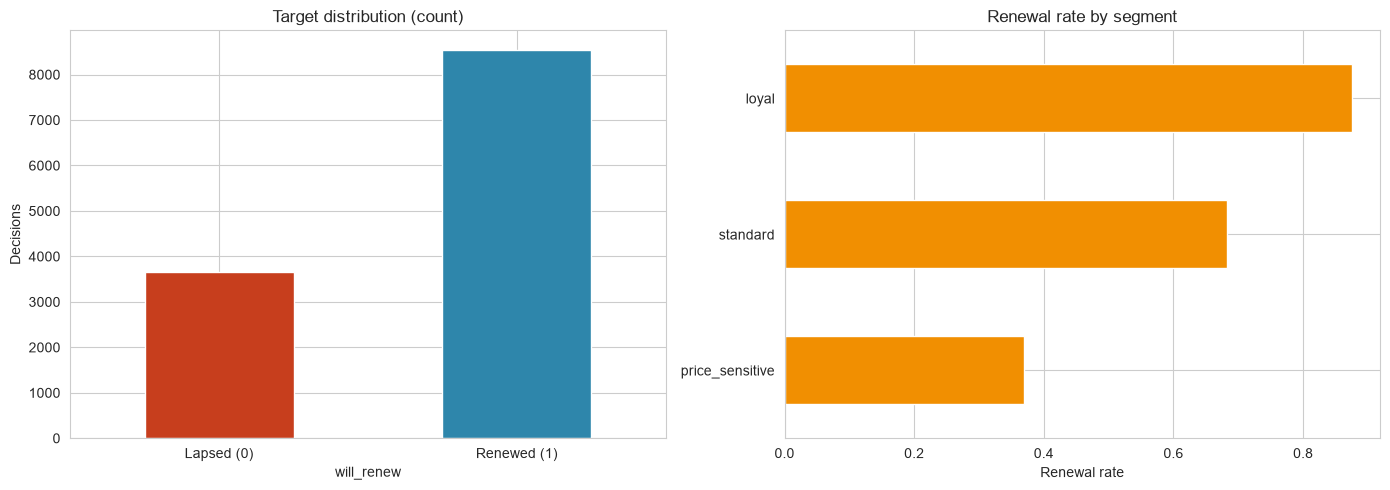

Saved: C:\Users\adebi\OneDrive\Desktop\DataScienceConsultingPortfolio\01_Portfolio-Projects\OkYeahInsight-Analytics\GuardianShield-Insurance\Engagement-1-Customer-Renewal\images\target_distribution.png


In [3]:
# ============================================
# TARGET DISTRIBUTION
# ============================================

print("Target distribution (will_renew):")
print(renewals["will_renew"].value_counts(normalize=True).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

renewals["will_renew"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=["#C73E1D", "#2E86AB"]
)
axes[0].set_title("Target distribution (count)")
axes[0].set_xlabel("will_renew")
axes[0].set_ylabel("Decisions")
axes[0].set_xticklabels(["Lapsed (0)", "Renewed (1)"], rotation=0)

renewals.groupby("segment")["will_renew"].mean().sort_values().plot(
    kind="barh", ax=axes[1], color="#F18F01"
)
axes[1].set_title("Renewal rate by segment")
axes[1].set_xlabel("Renewal rate")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved: {IMAGES_DIR / 'target_distribution.png'}")

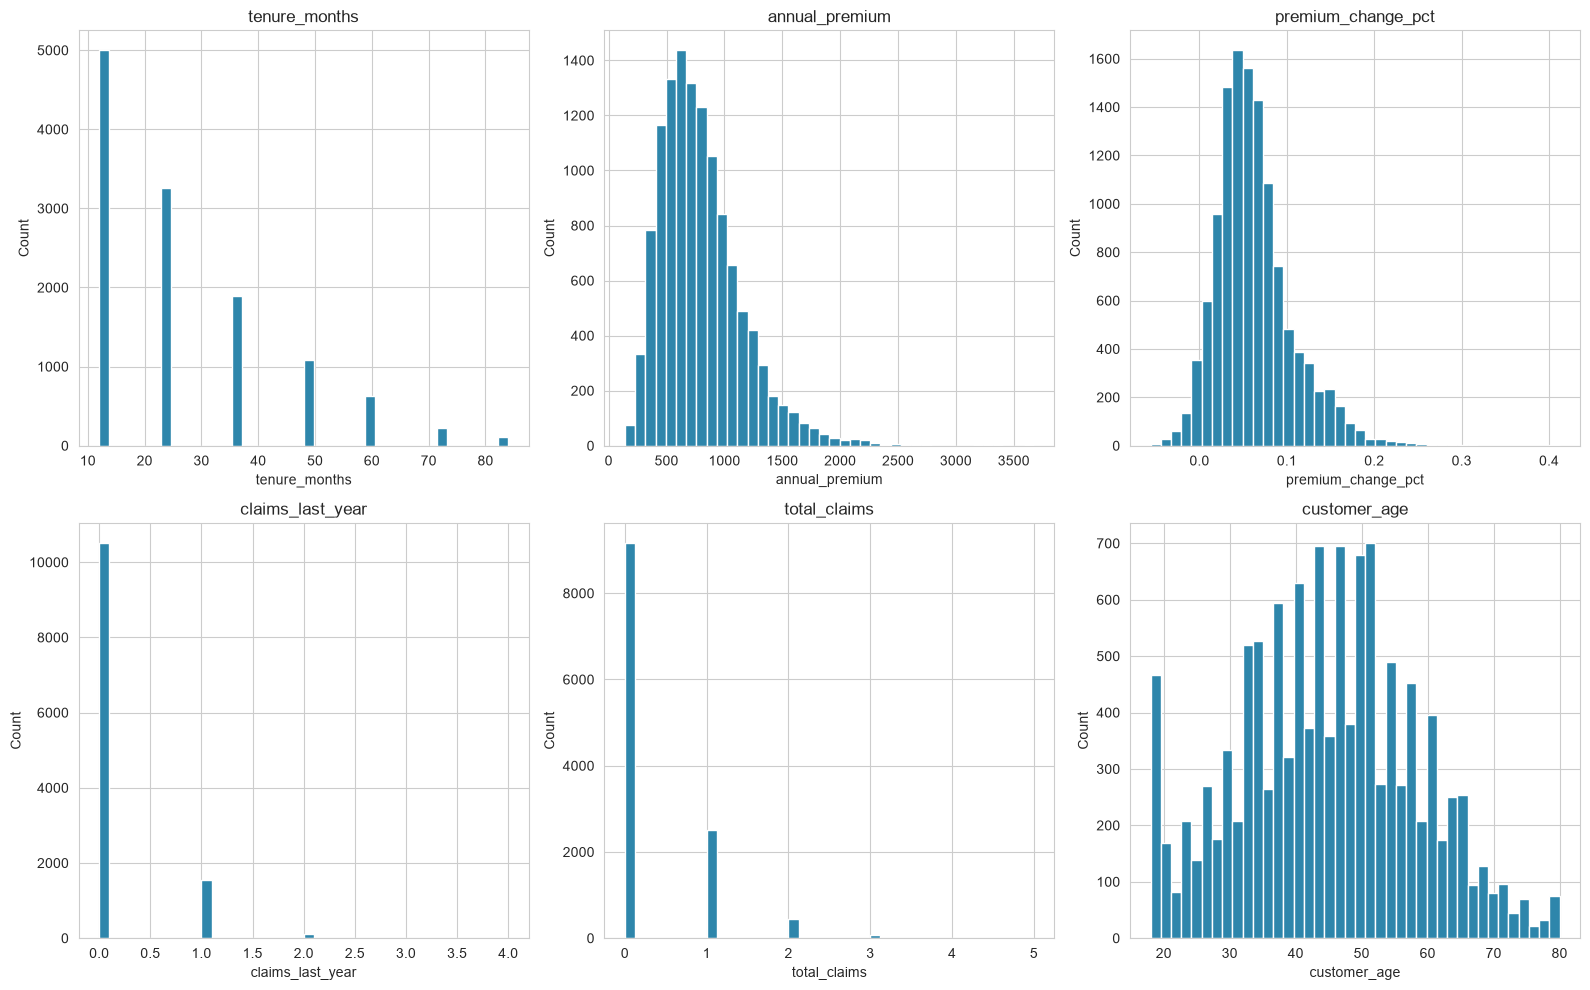

In [4]:
# ============================================
# FEATURE DISTRIBUTIONS
# ============================================

numeric_cols = [
    "tenure_months", "annual_premium", "premium_change_pct",
    "claims_last_year", "total_claims", "customer_age"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(renewals[col], bins=40, color="#2E86AB", edgecolor="white")
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

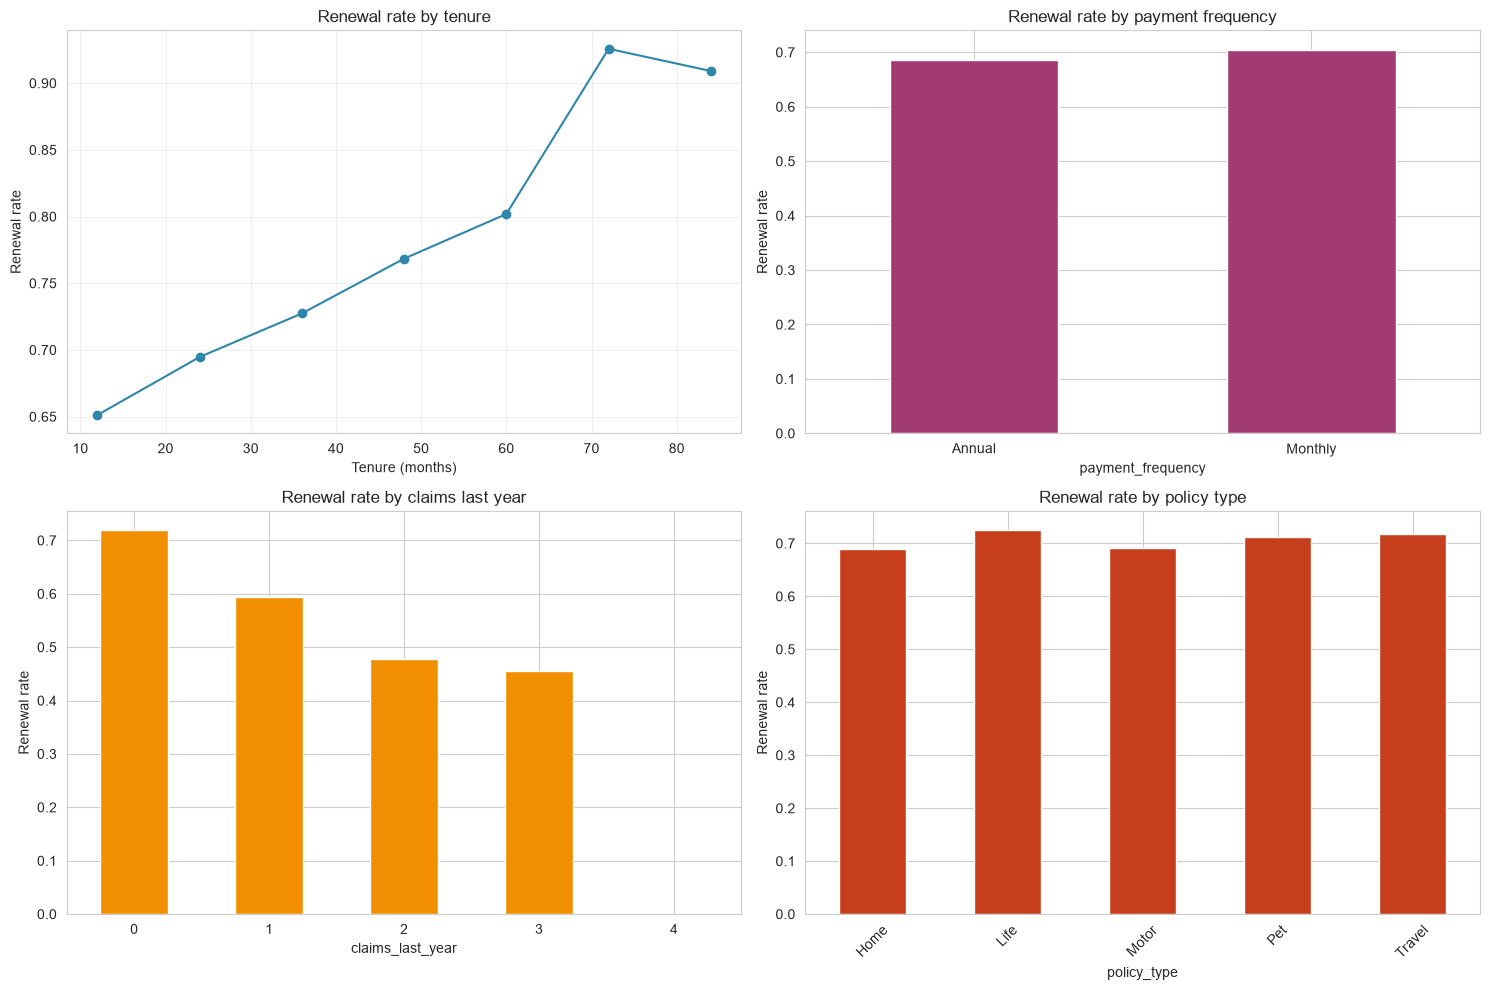

In [7]:
# ============================================
# RENEWAL RATE BY FEATURE
# ============================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# By tenure
renewals.groupby("tenure_months")["will_renew"].mean().plot(
    marker="o", ax=axes[0, 0], color="#2E86AB"
)
axes[0, 0].set_title("Renewal rate by tenure")
axes[0, 0].set_xlabel("Tenure (months)")
axes[0, 0].set_ylabel("Renewal rate")
axes[0, 0].grid(True, alpha=0.3)

# By payment frequency
renewals.groupby("payment_frequency")["will_renew"].mean().plot(
    kind="bar", ax=axes[0, 1], color="#A23B72"
)
axes[0, 1].set_title("Renewal rate by payment frequency")
axes[0, 1].set_xticklabels(axes[0, 1].get_xticklabels(), rotation=0)
axes[0, 1].set_ylabel("Renewal rate")

# By claims last year
renewals.groupby("claims_last_year")["will_renew"].mean().plot(
    kind="bar", ax=axes[1, 0], color="#F18F01"
)
axes[1, 0].set_title("Renewal rate by claims last year")
axes[1, 0].set_xticklabels(axes[1, 0].get_xticklabels(), rotation=0)
axes[1, 0].set_ylabel("Renewal rate")

# By policy type
renewals.groupby("policy_type")["will_renew"].mean().plot(
    kind="bar", ax=axes[1, 1], color="#C73E1D"
)
axes[1, 1].set_title("Renewal rate by policy type")
axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=45)
axes[1, 1].set_ylabel("Renewal rate")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "renewal_rate_by_feature.png", dpi=150, bbox_inches="tight")
plt.show()

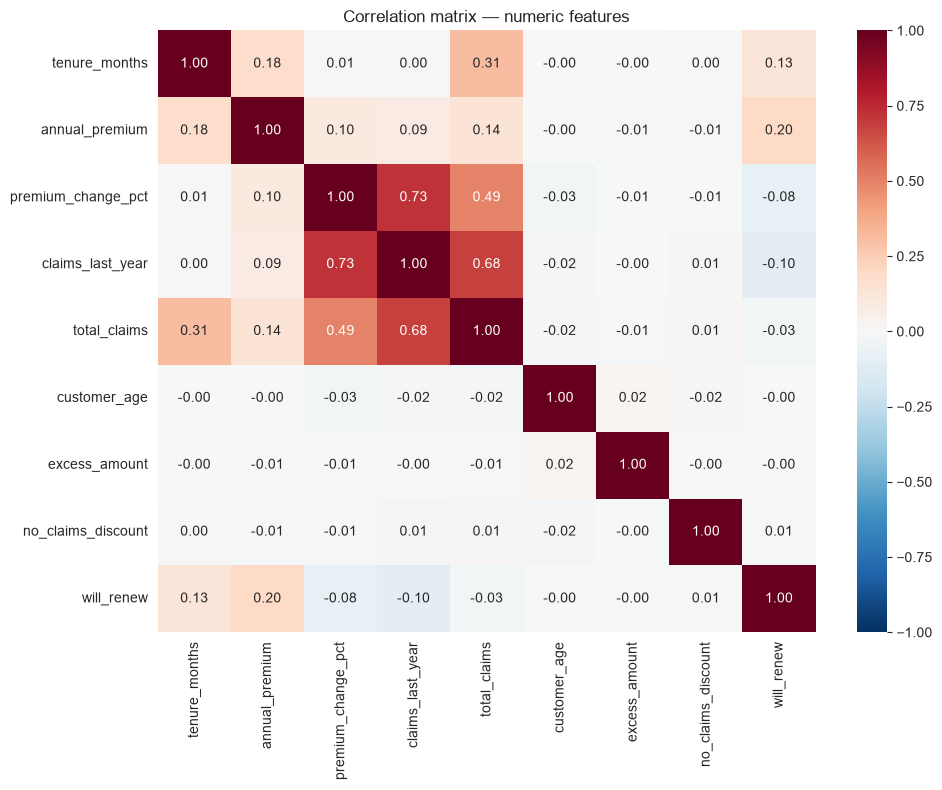


Correlation with will_renew (sorted by absolute value):
annual_premium        0.196
tenure_months         0.125
claims_last_year     -0.104
premium_change_pct   -0.081
total_claims         -0.030
no_claims_discount    0.007
excess_amount        -0.005
customer_age         -0.004
Name: will_renew, dtype: float64


In [8]:
# ============================================
# CORRELATION WITH TARGET
# ============================================

numeric_features = [
    "tenure_months", "annual_premium", "premium_change_pct",
    "claims_last_year", "total_claims", "customer_age",
    "excess_amount", "no_claims_discount", "will_renew"
]

corr = renewals[numeric_features].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, vmin=-1, vmax=1, ax=ax
)
ax.set_title("Correlation matrix — numeric features")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nCorrelation with will_renew (sorted by absolute value):")
print(
    corr["will_renew"]
    .drop("will_renew")
    .sort_values(key=abs, ascending=False)
    .round(3)
)

## Key Insights

### 1. Target balance
- 70% renewals, 30% lapses — a healthy imbalance for classification

### 2. Segment separation
- Loyal: 87.5% | Standard: 68.2% | Price-sensitive: 37.0%
- Segment is strongly predictive, but we will not use it as a feature
  (the model must learn from behavioural signals)

### 3. Tenure is the strongest behavioural signal
- Renewal rate rises from 65% (12 months) to 93% (72 months)
- Critical retention window: first 24–36 months

### 4. Claims strongly reduce renewal
- 0 claims: 72% renewal
- 1 claim: 60%
- 2+ claims: 45–48%
- Each claim costs ~10 percentage points

### 5. Payment frequency and policy type do NOT predict renewal
- Annual vs monthly: 69% vs 70%
- All five policy types: 68–72%

### 6. Correlation structure
- Premium change ↔ claims: 0.73 (claims cause premium rises)
- Claims ↔ total claims: 0.68
- These are expected — no spurious relationships

### 7. Next steps
- Feature engineering: encode categoricals, create derived features
- Modelling: Logistic Regression, Random Forest, XGBoost
- Evaluation: threshold tuning, SHAP, business impact